In [1]:
import pandas as pd
import numpy as np
from scipy.signal import cont2discrete
from scipy.linalg import expm, inv
from matplotlib import pyplot as plt

# Data Loading
The data we will be exploring in this example is a very simple data set, it has no gains, the indoor temperature varies due to the external temperature variation

The data frequency is hourly. So 

In [2]:
df = pd.read_csv("data.csv", delimiter=";").set_index("Step")
df.drop(df.index[-1], axis=0, inplace=True)
data = df[df['Month'].isin([6, 7, 8])]  ## keep only summer months

sT = 3600 * 24
data.index = data.index*3600 / sT  # Change time scale to days
train_data = data.iloc[0:1000]
test_data = data.iloc[1000:]

# State space model
In this tutorial we will only use a state space model defining a single thermal zone. We will use a second order RC model (2R2C)

$$x = A x_t+Bu_t+w_t$$
$$y_t=Cx_t+v_t$$

where:
$$w_t∼N(0,Q)$$
$$v_t∼N(0,R)$$

* $x_t$: is a p-dimensional vector of all states calculated by the model (in our context it is the temperatures calculated by the model for all nodes (indoor, and wall ...)). For example in a 1R1C model the indoor temperature is the only model output, so in this case p=1. In a 2R2C model we compute the indoor and the envelope temperature, thus p=2 etc.
  
* $y_t$ is a q-dimensional vector of output temperatures that will be compared to measurements (typically q = 1 and y(t) is the indoor temperature) since this is the observable measurable quantity, the walls temperatures are normally hidden states that we do not measure (observe)
  
* $u_t$ is an r-dimensional vector of boundary conditions (e.g. heat input, solar radiation, outdoor temperature, ...)

* $w_t$ is the process noise
  
* $v_t$ is the measurement noise

* $Q$ is a pxp covariance matrix describing the uncertainty of the states

* $R$ is qxq matrix describing the uncertainty of the measurements

# 2R2C model 
$$x = A x_t+Bu_t+w_t$$
$$y_t=Cx_t+v_t$$

where:

$$ A = \begin{bmatrix}
    -1/C_1R_1 - 1/C_1R_2 & 1/C_1R_2 \\
    1/C_2R_2  & -1/C_2R_2
\end{bmatrix} $$

$$ B = \begin{bmatrix}
    1/C_1R_1  & 0 \\
    0  & 1/C_2 
\end{bmatrix} $$

$$ C = \begin{bmatrix}
    0  & 1 
\end{bmatrix} $$

$$ Q = \begin{bmatrix}
    {q_1}^2  & 0 \\
    0 &  {q_2}^2
\end{bmatrix} $$

$$ R = \begin{bmatrix}
    {r}^2
\end{bmatrix} $$

In the following cell you have to build a class containing matrices A, B and C; in subsequent cells you will be using it to access the different matrices

In [21]:
def build_continuous_matrices(R1, R2, C1, C2, qi, qe, r):
    A = np.array([
        [-(1/(C1*R1) + 1/(C1*R2)),  1/(C1*R2)],
        [ 1/(C2*R2),               -1/(C2*R2)]
    ])

    B = np.array([
        [1/(C1*R1),  0],  # T_ext, q
        [0,           1/C2]
    ])
    
    C = np.array([[0, 1]])  # Output: indoor air temp

    # System and measurement error covariance matrices
    Qc = np.diag([qi**2, qe**2])
    Rc = np.array([[r ** 2]])
    return A, B, C, Qc, Rc

To work with state-space models on a digital computer or controller, we discretize them so we can compute the states at each discrete time step instead of continuously.

$$x_{[k+1]}=F​x_k + B​u_k + w[k]$$

Ad​=eATs​

Bd​=Ac−1​(Ad​−I)Bc​​

R = Rc / dt

Qd​=∫0Ts​​eAτQc​eA⊤τdτ
Direct evaluation of this integral can be tricky.

Van Loan method uses a matrix exponential of an augmented block matrix to compute it efficiently.

In teh following cell implement these discritisations

In [6]:
def discretize(time_step: float, Ac: np.ndarray, Bc: np.ndarray, Qc=None, Rc=None):
    F = expm(Ac * time_step)
    G = inv(Ac) @ (F - np.eye(Ac.shape[0])) @ Bc
    if Qc is None or Rc is None:
        return F, G
    else:            
        result = cont2discrete((Ac, np.eye(Ac.shape[0]), np.eye(Ac.shape[0]), Qc), time_step, method='zoh')
        Q = result[3]
        # Measurement error covariance matrix (discrete)
        R = Rc / time_step
        return F, G, Q, R

Now we can start the kalman filter. In the following cell, you will build a kalman filter. In this part we still are not computing the likelihood function but we are just running the kalman filter forward without any <>

In [ ]:
time = data.index
T_in = np.array(data['Tint'])
T_ext = np.array(data['Text'])
q = np.array(data['Qheat'])
time_step = time[1] - time[0]  # time step in days

R1 = 0.1  # K/W
R2 = 0.1    # K/W
C1 = 3     # J/K
C2 =  3    # J/K

Ac, Bc, H, Qc, Rc = build_continuous_matrices(R1, R2, C1, C2, qi=1e2, qe=1e2, r=1e0)
F, G, Q, R = discretize(time_step, Ac, Bc, Qc, Rc)


## Initialisation
uk = np.vstack([T_ext, q])
xk = np.zeros((F.shape[0], uk.shape[1]))  # initial state
P = np.eye(2)  # initial state
xk[:, 0] = np.array([T_ext[0], T_in[0]])  # initial external temp

# Initialize as lists to preserve dimensions when appending
x_s = []
P_s = []
x_updates = []
P_updates = []

for i in range(1, len(time)):
    uk = np.vstack([T_ext[i], q[i]])
    
    # Prediction step
    x_ = F @ np.array([xk[:, i-1]]).T + G @ uk
    P_ = F @ P @ F.T + Q  # process noise

    # Innovation
    y = np.array([[T_in[i]]])
    epsilun = y - (H @ x_)
    Sigma = H @ P_ @ H.T + R  # innovation covariance
    Kt = P_ @ H.T @ inv(Sigma)  # Kalman gain

    # Update
    new_state = x_ + Kt @ epsilun
    xk[:, i] = new_state[:,0]
    P = (np.eye(2) - Kt @ H) @ P_  # updated estimate covariance

    x_s.append(x_)
    P_s.append(P_)
    x_updates.append(new_state)
    P_updates.append(P)



In [49]:
i = 1
uk = np.vstack([T_ext[i], q[i]])

# Prediction step
x_ = F @ np.array([xk[:, i-1]]).T + G @ uk
P_ = F @ P @ F.T + Q  # process noise
x_

array([[15.28011824],
       [15.69665188]])

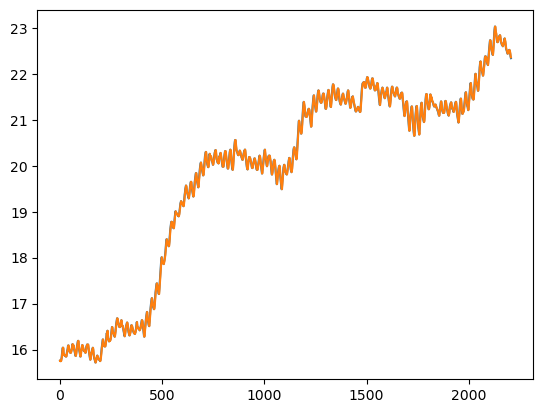

In [37]:
plt.plot(x_updates[1,:])
plt.plot(x_s[1,:])

In [ ]:
def run_KF(data, F, G, H, Q, R, update=True):        
    data = test_data

    time = data.index
T_in = np.array(data['Tint'])
T_ext = np.array(data['Text'])
q = np.array(data['Qheat'])
time_step = time[1] - time[0]  # time step in days

R1 = 2.5e-3  # K/W
R2 = 5e-4    # K/W
C1 = 2e7     # J/K
C2 = 1e6     # J/K

Ac, Bc, H, Qc, Rc = build_continuous_matrices(R1, R2, C1, C2, qi=1e2, qe=1e2, r=1e0)
F, G, Q, R = discretize(time_step, Ac, Bc, Qc, Rc)


## Initialisation
uk = np.vstack([T_ext, q])
xk = np.zeros((F.shape[0], uk.shape[1]))  # initial state
P = np.eye(2)  # initial state
xk[:, 0] = np.array([T_ext[0], T_in[0]])  # initial external temp

    x_s = []
    P_s = []
    x_updates = []
    P_updates = []

    for i in range(1, len(time)):
        uk = np.vstack([T_ext[i], q[i]])
        
        # Prediction step
        x_ = F @ np.array([xk[:, i-1]]).T + G @ uk
        P_ = F @ P @ F.T + Q  # process noise

       # Innovation
        y = np.array([[T_in[i]]])
        epsilun = y - (H @ x_)
        Sigma = H @ P_ @ H.T + R  # innovation covariance
        Kt = P_ @ H.T @ inv(Sigma)  # Kalman gain

        # Update
        new_state = x_ + Kt @ epsilun
        xk[:, i] = new_state[:,0]
        P = (np.eye(2) - Kt @ H) @ P_  # updated estimate covariance

        x_s.append(x_)
        P_s.append(P_)
        x_updates.append(new_state)
        P_updates.append(P)